<a href="https://colab.research.google.com/github/Vikrampaswan07/Basic-Quantum-Computing/blob/main/TwoEntangleQubit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Possible challenge: Write a Qiskit program that creates two entangled qubits, measures them, and displays the output distribution.


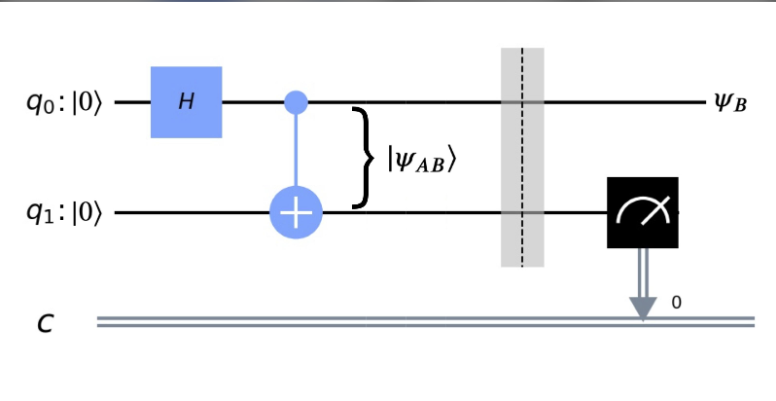

The circuit applies:
1. A Hadamard gate \(H\) to qubit 0.
2. A CNOT gate with qubit 0 as control and qubit 1 as target.
3. Measurement of both qubits.

In [ ]:
pip install qiskit qiskit_aer matplotlib pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 25.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 29.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 32.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.2 MB/s eta 0:00:00


{'11': 501, '00': 499}
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 
dict_keys(['11', '00']) dict_values([501, 499])


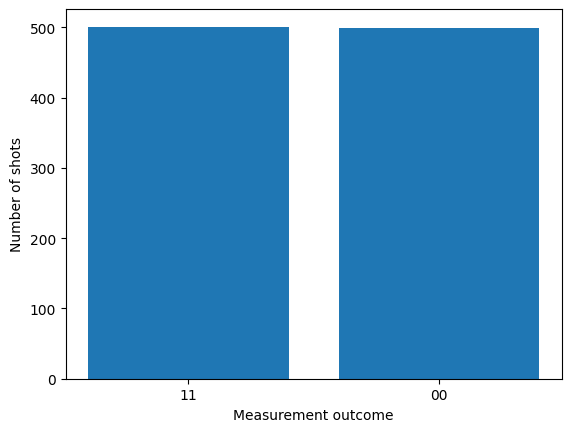

In [ ]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt

# Create a circuit with two qubits
qc = QuantumCircuit(2, 2)

# Create superposition
qc.h(0)

# Entangle the qubits
qc.cx(0, 1)

# Measure both qubits
qc.measure([0, 1], [0, 1])

# Run the simulation
backend = AerSimulator()
result = backend.run(qc, shots=1000).result()

counts = result.get_counts()
print(counts)

# Plot the results
print(qc.draw())
# qc.draw("mpl")
print(counts.keys(), counts.values())
plt.bar(counts.keys(), counts.values())
plt.xlabel("Measurement outcome")
plt.ylabel("Number of shots")
plt.show()

Challenge A: Simulate a random quantum bit
Apply an H gate to one qubit, measure it repeatedly and check whether the results are approximately 50% zero and 50% one.
Skills: superposition, measurement, statistical sampling.

In [ ]:
qc = QuantumCircuit(1, 1)
qc.h(0)
qc.measure(0, 0)
simulator = AerSimulator()
result = simulator.run(qc, shots=1000).result()
counts = result.get_counts()
print(counts)

# Step 7: Calculate percentages
zero_count = counts.get('0', 0)
one_count = counts.get('1', 0)

zero_percent = zero_count / 1000 * 100
one_percent = one_count / 1000 * 100

print(f"Probability of 0: {zero_percent:.2f}%")
print(f"Probability of 1: {one_percent:.2f}%")

# Step 8: Display circuit
print(qc.draw())

{'0': 512, '1': 488}
Probability of 0: 51.20%
Probability of 1: 48.80%
     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 


Challenge B: Search for a marked item
Demonstrate a small version of Grover's algorithm, which amplifies the probability of measuring a marked solution in an unstructured search space.
Skills: oracle, amplitude amplification, quantum algorithms.

After superposition:
{'11': 276, '10': 227, '00': 242, '01': 255}

Grover circuit:
     ┌───┐┌───┐   ┌───┐┌───┐┌───┐   ┌───┐┌───┐┌─┐   
q_0: ┤ H ├┤ X ├─■─┤ X ├┤ H ├┤ X ├─■─┤ X ├┤ H ├┤M├───
     ├───┤└───┘ │ ├───┤├───┤└───┘ │ ├───┤├───┤└╥┘┌─┐
q_1: ┤ H ├──────■─┤ H ├┤ X ├──────■─┤ X ├┤ H ├─╫─┤M├
     └───┘        └───┘└───┘        └───┘└───┘ ║ └╥┘
c: 2/══════════════════════════════════════════╩══╩═
                                               0  1 

After one Grover iteration:
{'10': 1000}


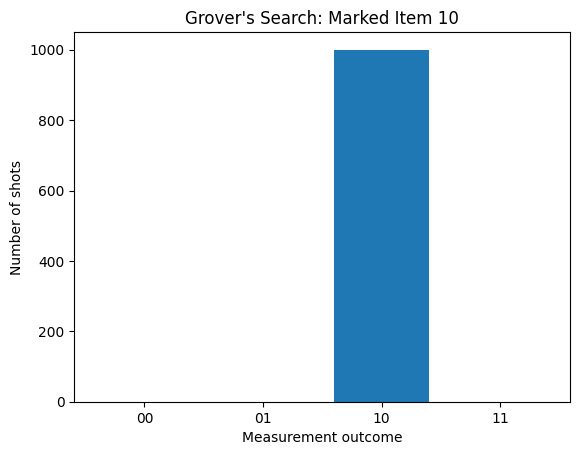

In [ ]:

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt

# Step 1: Oracle for marked item |10>
def oracle(qc):
    qc.x(0)
    qc.cz(0, 1)
    qc.x(0)

# Step 2: Grover diffusion operator
def diffuser(qc):
    qc.h([0, 1])
    qc.x([0, 1])
    qc.cz(0, 1)
    qc.x([0, 1])
    qc.h([0, 1])

simulator = AerSimulator()

# Step 3: Demonstrate superposition separately
superposition = QuantumCircuit(2, 2)
superposition.h([0, 1])
superposition.measure([0, 1], [0, 1])

result1 = simulator.run(superposition, shots=1000).result()
counts1 = result1.get_counts()

print("After superposition:")
print(counts1)

# Step 4: Build the complete Grover circuit
qc = QuantumCircuit(2, 2)
qc.h([0, 1])       # Equal superposition
oracle(qc)         # Mark |10>
diffuser(qc)       # Amplify marked state
qc.measure([0, 1], [0, 1])

print("\nGrover circuit:")
print(qc.draw())

# Step 5: Simulate 1000 measurements
result = simulator.run(qc, shots=1000).result()
counts = result.get_counts()

print("\nAfter one Grover iteration:")
print(counts)

# Step 6: Plot final results
outcomes = ['00', '01', '10', '11']
values = [counts.get(x, 0) for x in outcomes]

plt.bar(outcomes, values)
plt.xlabel("Measurement outcome")
plt.ylabel("Number of shots")
plt.title("Grover's Search: Marked Item 10")
plt.show()


Challenge C: Solve a small optimization problem
Represent a small scheduling, routing or graph problem mathematically, then explore QAOA or a simpler quantum-inspired baseline.
Skills: optimization, cost functions, constraints and benchmarking.

In [ ]:

import random
from itertools import product

# Four vertices and five edges
n = 4
edges = [(0, 1), (1, 2), (2, 3), (3, 0), (0, 2)]

def cut_value(bits):
    """Count edges whose endpoints belong to different groups."""
    return sum(bits[i] != bits[j] for i, j in edges)

# 1. Exact classical search
all_solutions = list(product([0, 1], repeat=n))
scores = [(bits, cut_value(bits)) for bits in all_solutions]

best_bits, best_score = max(scores, key=lambda item: item[1])

print("Exact optimum:", best_score)
print("Best assignment:", best_bits)

# 2. Random-search baseline
random.seed(42)
trials = 100
random_scores = []

for _ in range(trials):
    bits = tuple(random.randint(0, 1) for _ in range(n))
    random_scores.append(cut_value(bits))

print("Random-search best:", max(random_scores))
print("Random-search average:",
      round(sum(random_scores) / trials, 2))


Exact optimum: 4
Best assignment: (0, 1, 0, 1)
Random-search best: 4
Random-search average: 2.56


Challenge D: Quantum machine learning
Build a small variational quantum classifier using a tiny dataset, encode features into a circuit, and compare its results with a classical model.
Skills: data encoding, parameterized circuits, classification and evaluation.

Training samples: 75
Testing samples: 25

Quantum training completed.
Final training loss: 0.1177
Optimizer success: True

Quantum VQC
Accuracy : 0.92
Precision: 1.0
Recall   : 0.833
F1-score : 0.909

Classical Logistic Regression
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0


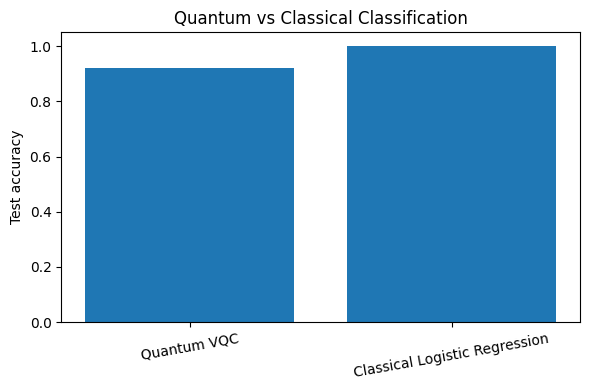

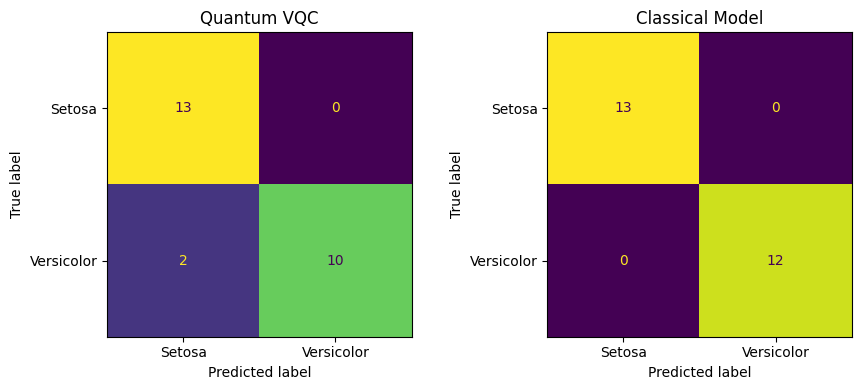

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)

from scipy.optimize import minimize

# --------------------------------------------------
# STEP 1: Load a tiny binary classification dataset
# --------------------------------------------------
iris = load_iris()

# Select Setosa and Versicolor, using two features
X = iris.data[:100, [0, 2]]
y = iris.target[:100]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Encode features as angles between 0 and pi
scaler = MinMaxScaler(feature_range=(0, np.pi))
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# --------------------------------------------------
# STEP 2: Define the variational quantum circuit
# --------------------------------------------------
def quantum_probability(features, weights):
    qc = QuantumCircuit(2)

    # Data encoding
    qc.ry(float(features[0]), 0)
    qc.ry(float(features[1]), 1)

    # Two trainable layers
    for layer in range(2):
        qc.ry(float(weights[2 * layer]), 0)
        qc.ry(float(weights[2 * layer + 1]), 1)
        qc.cx(0, 1)

    # Exact statevector simulation
    state = Statevector.from_instruction(qc)

    # Probability that qubit 0 is measured as 1
    probabilities = state.probabilities(qargs=[0])
    return float(probabilities[1])

# --------------------------------------------------
# STEP 3: Define the training loss
# --------------------------------------------------
def loss_function(weights):
    epsilon = 1e-10
    losses = []

    for features, label in zip(X_train, y_train):
        p1 = np.clip(
            quantum_probability(features, weights),
            epsilon, 1 - epsilon
        )

        # Binary cross-entropy
        loss = -(
            label * np.log(p1)
            + (1 - label) * np.log(1 - p1)
        )
        losses.append(loss)

    return float(np.mean(losses))

# --------------------------------------------------
# STEP 4: Train the quantum classifier
# --------------------------------------------------
np.random.seed(42)
initial_weights = np.random.uniform(-0.5, 0.5, size=4)

optimization = minimize(
    loss_function,
    initial_weights,
    method="COBYLA",
    options={"maxiter": 100}
)

trained_weights = optimization.x

print("\nQuantum training completed.")
print("Final training loss:", round(optimization.fun, 4))
print("Optimizer success:", optimization.success)

# --------------------------------------------------
# STEP 5: Make quantum predictions
# --------------------------------------------------
def quantum_predict(features):
    p1 = quantum_probability(features, trained_weights)
    return int(p1 >= 0.5)

y_pred_quantum = np.array([
    quantum_predict(features) for features in X_test
])

# --------------------------------------------------
# STEP 6: Train a classical baseline
# --------------------------------------------------
classical_model = LogisticRegression(max_iter=1000)
classical_model.fit(X_train, y_train)

y_pred_classical = classical_model.predict(X_test)

# --------------------------------------------------
# STEP 7: Compare model performance
# --------------------------------------------------
def evaluate_model(name, y_true, y_pred):
    print(f"\n{name}")
    print("Accuracy :", round(accuracy_score(y_true, y_pred), 3))
    print("Precision:", round(
        precision_score(y_true, y_pred, zero_division=0), 3
    ))
    print("Recall   :", round(
        recall_score(y_true, y_pred, zero_division=0), 3
    ))
    print("F1-score :", round(
        f1_score(y_true, y_pred, zero_division=0), 3
    ))

evaluate_model("Quantum VQC", y_test, y_pred_quantum)
evaluate_model("Classical Logistic Regression",
               y_test, y_pred_classical)

# --------------------------------------------------
# STEP 8: Plot accuracy and confusion matrices
# --------------------------------------------------
quantum_accuracy = accuracy_score(y_test, y_pred_quantum)
classical_accuracy = accuracy_score(y_test, y_pred_classical)

plt.figure(figsize=(6, 4))
plt.bar(
    ["Quantum VQC", "Classical Logistic Regression"],
    [quantum_accuracy, classical_accuracy]
)
plt.ylabel("Test accuracy")
plt.ylim(0, 1.05)
plt.title("Quantum vs Classical Classification")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred_quantum),
    display_labels=["Setosa", "Versicolor"]
).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Quantum VQC")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred_classical),
    display_labels=["Setosa", "Versicolor"]
).plot(ax=axes[1], colorbar=False)
axes[1].set_title("Classical Model")

plt.tight_layout()
plt.show()


Practice question: Angle encoding using Qiskit
Problem: Given the input vector \(x=[0.2,0.7]\), encode its two features into two qubits using \(R_y\) gates. Draw the circuit and inspect the resulting quantum state.

Encoder circuit:
     ┌─────────┐
q_0: ┤ Ry(0.2) ├
     ├─────────┤
q_1: ┤ Ry(0.7) ├
     └─────────┘

Encoded statevector:
[0.9347+0.j 0.0938+0.j 0.3412+0.j 0.0342+0.j]


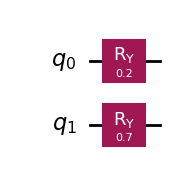

In [ ]:

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
import numpy as np

# Classical input features
x = [0.2, 0.7]

# Create a two-qubit encoder
qc = QuantumCircuit(2)

# Encode each feature as a rotation angle
qc.ry(x[0], 0)
qc.ry(x[1], 1)

print("Encoder circuit:")
print(qc.draw())

# Get the encoded quantum state
state = Statevector.from_instruction(qc)

print("\nEncoded statevector:")
print(np.round(state.data, 4))

# Visualize the circuit in Matplotlib
qc.draw("mpl")
